# SMS Spam Detection with Machine Learning

**Goal:** build a classifier that labels an SMS as *spam* or *ham* (legitimate), and tune it for the way a real spam filter is judged: **blocking spam without hiding genuine messages**.

**Dataset:** [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (5,574 labelled English SMS messages).

**Workflow**
1. Load and inspect the data
2. Exploratory data analysis
3. Text cleaning (duplicates removed first)
4. Train/test split + TF-IDF features
5. Compare models with cross-validation
6. Tune the decision threshold on a validation set
7. Final evaluation on the untouched test set
8. Error analysis, top spam words, save the model, predict new messages

## 0. Setup

In [1]:
import os
import re
import zipfile
from io import BytesIO
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, make_scorer,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

## 1. Load the data
The dataset is downloaded once from UCI and cached as `spam_dataset.csv`; later runs read the local copy.

In [2]:
DATA_PATH = "spam_dataset.csv"
URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    response = requests.get(URL, timeout=30)
    response.raise_for_status()
    with zipfile.ZipFile(BytesIO(response.content)) as z:
        with z.open("SMSSpamCollection") as f:
            df = pd.read_csv(f, sep="\t", header=None, names=["label", "message"])
    df.to_csv(DATA_PATH, index=False)

print("Shape:", df.shape)
df.head(10)

Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 2. Exploratory data analysis

In [3]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:\n", df["label"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Missing values:
 label      0
message    0
dtype: int64

Duplicate rows: 403

Class counts:
 label
ham     4825
spam     747
Name: count, dtype: int64


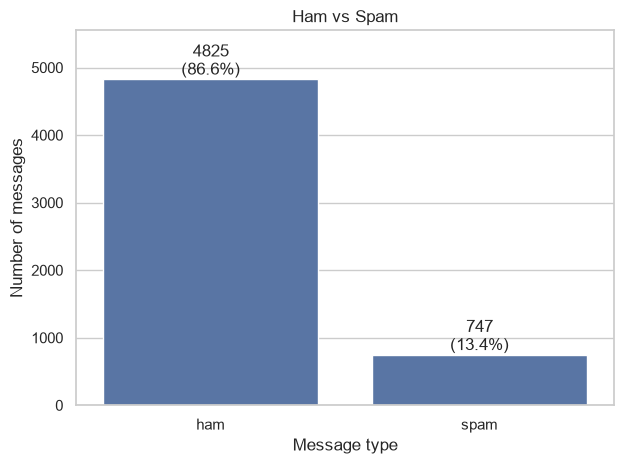

In [4]:
counts = df["label"].value_counts()
ax = sns.countplot(data=df, x="label", order=counts.index)
for i, label in enumerate(counts.index):
    ax.text(i, counts[label], f"{counts[label]}\n({counts[label] / len(df):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Ham vs Spam")
ax.set_xlabel("Message type")
ax.set_ylabel("Number of messages")
save_fig("01_class_distribution")
plt.show()

The classes are **imbalanced** (roughly 87% ham), so accuracy alone is misleading: a model that always says "ham" would score about 87%. We judge models on **precision, recall and F1 for the spam class**.

label              ham   spam
char_len count  4825.0  747.0
         mean     71.5  138.7
         std      58.4   28.9
         min       2.0   13.0
         25%      33.0  133.0
         50%      52.0  149.0
         75%      93.0  157.0
         max     910.0  223.0
word_len count  4825.0  747.0
         mean     14.3   23.9
         std      11.5    5.8
         min       1.0    2.0
         25%       7.0   22.0
         50%      11.0   25.0
         75%      19.0   28.0
         max     171.0   35.0


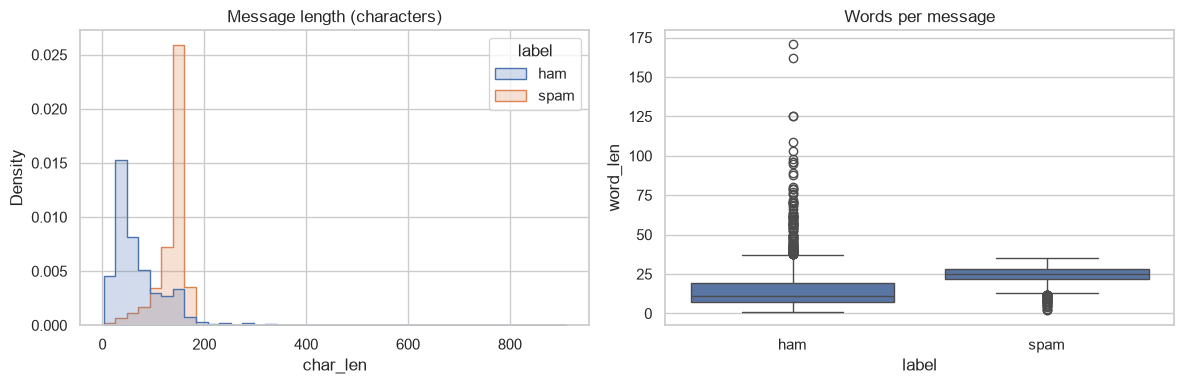

In [5]:
df["char_len"] = df["message"].str.len()
df["word_len"] = df["message"].str.split().str.len()

print(df.groupby("label")[["char_len", "word_len"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="char_len", hue="label", bins=40, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Message length (characters)")
sns.boxplot(data=df, x="label", y="word_len", ax=axes[1])
axes[1].set_title("Words per message")
save_fig("02_message_length")
plt.show()

Spam messages tend to be longer than ham, a useful signal, although the TF-IDF features below capture most of the useful information.

## 3. Text cleaning

Order matters here:
1. **Remove exact duplicates first**, so copies of the same message cannot land in both train and test sets (data leakage).
2. Replace URLs, currency symbols and numbers with placeholder tokens instead of deleting them, because these are strong spam signals (prize amounts, phone numbers, links).
3. Lowercase, strip punctuation, drop stop words but keep negations (`not`, `no`, `nor`).

> Placeholders are lowercase words (`urltoken`, `numtoken`, `currencytoken`) so they survive the later "letters only" filter.

In [6]:
# Drop duplicates before any splitting
before = len(df)
df = df.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate messages -> {len(df)} remain")
print(df["label"].value_counts())

Removed 403 duplicate messages -> 5169 remain
label
ham     4516
spam     653
Name: count, dtype: int64


In [7]:
try:
    import nltk
    try:
        nltk.data.find("corpora/stopwords")
    except LookupError:
        nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words("english"))
except Exception:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    stop_words = set(ENGLISH_STOP_WORDS)

# Keep negations; they can change meaning
custom_stop_words = stop_words - {"not", "no", "nor"}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"[£$€]", " currencytoken ", text)
    text = re.sub(r"\d+", " numtoken ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [w for w in text.split() if w not in custom_stop_words]
    return " ".join(words)

df["clean_message"] = df["message"].apply(clean_text)
df[["label", "message", "clean_message"]].head(8)

,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry numtoken wkly comp win fa cup final...
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though
5,spam,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling numtoken week no word back...
6,ham,Even my brother is not like to speak with me. ...,even brother not like speak treat like aids pa...
7,ham,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...


In [8]:
# Some messages may become empty after cleaning
empty = (df["clean_message"].str.strip() == "").sum()
print("Empty after cleaning:", empty)
df = df[df["clean_message"].str.strip() != ""].reset_index(drop=True)
print("Final dataset:", df.shape)

Empty after cleaning: 4
Final dataset: (5165, 5)


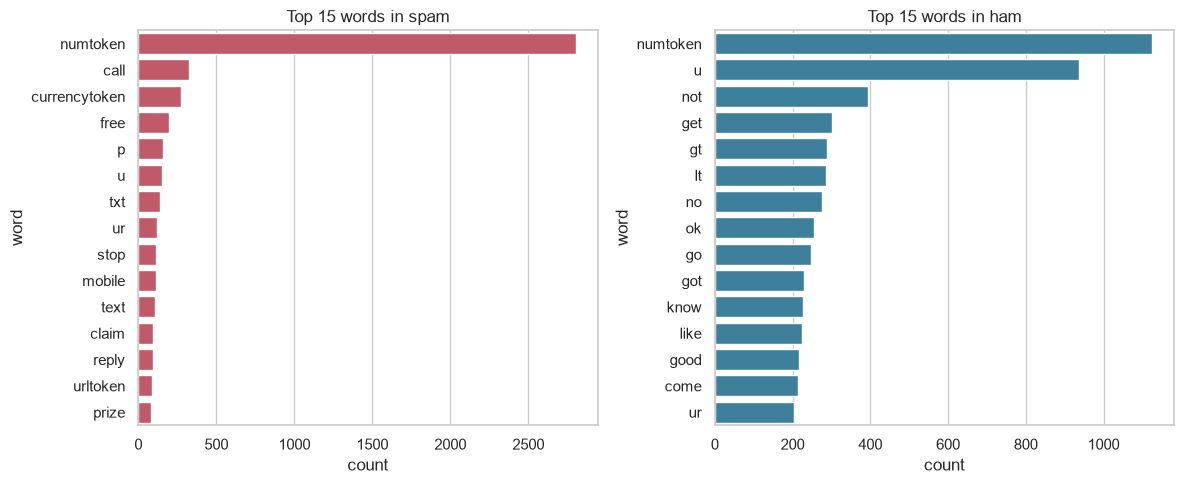

In [9]:
# Most frequent words per class
def top_words(label, n=15):
    words = " ".join(df.loc[df["label"] == label, "clean_message"]).split()
    return pd.DataFrame(Counter(words).most_common(n), columns=["word", "count"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label, color in zip(axes, ["spam", "ham"], ["#d1495b", "#2e86ab"]):
    tw = top_words(label)
    sns.barplot(data=tw, y="word", x="count", color=color, ax=ax)
    ax.set_title(f"Top 15 words in {label}")
save_fig("03_top_words")
plt.show()

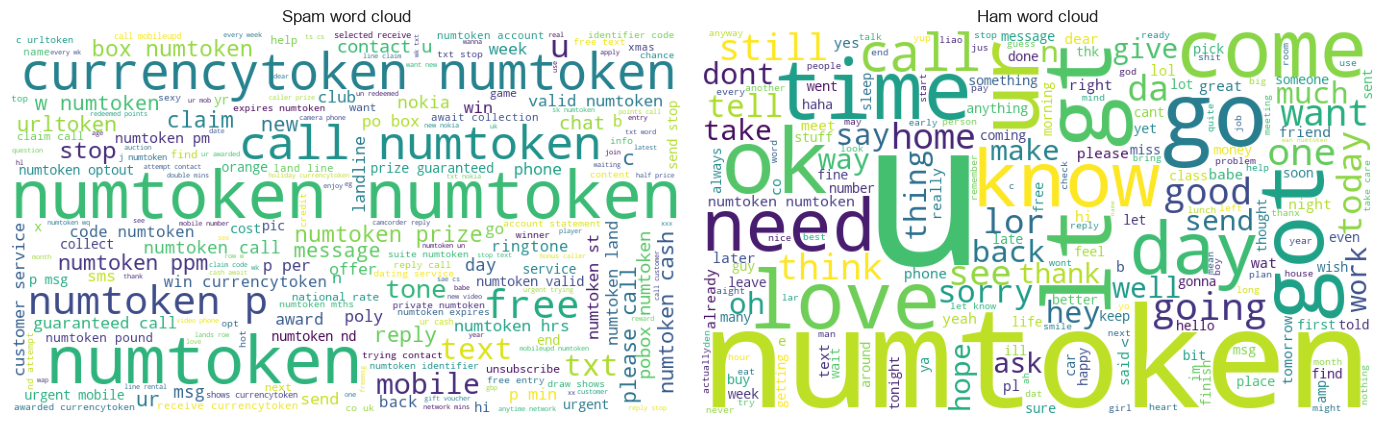

In [10]:
# Optional word clouds (pip install wordcloud)
try:
    from wordcloud import WordCloud
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, label in zip(axes, ["spam", "ham"]):
        text = " ".join(df.loc[df["label"] == label, "clean_message"])
        ax.imshow(WordCloud(width=700, height=400, background_color="white").generate(text))
        ax.set_title(f"{label.title()} word cloud")
        ax.axis("off")
    save_fig("04_wordclouds")
    plt.show()
except ImportError:
    print("wordcloud not installed - skipping (pip install wordcloud)")

## 4. Train/test split
A stratified 80/20 split keeps the spam ratio equal in both sets. The **test set stays untouched** until the final evaluation. TF-IDF is part of each model pipeline, so it is always fitted on training data only.

In [11]:
X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Spam share  train: {:.1%}  test: {:.1%}".format((y_train == "spam").mean(), (y_test == "spam").mean()))

Train: (4132,) | Test: (1033,)
Spam share  train: 12.6%  test: 12.7%


## 5. Compare models with cross-validation
Three models, each inside a pipeline (TF-IDF + classifier), scored with 5-fold stratified CV on the training set only.

In [12]:
def make_pipeline(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
        ("clf", clf),
    ])

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, class_weight="balanced", random_state=RANDOM_STATE),
}
pipelines = {name: make_pipeline(clf) for name, clf in models.items()}

scoring = {
    "precision": make_scorer(precision_score, pos_label="spam", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="spam"),
    "f1": make_scorer(f1_score, pos_label="spam"),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, pipe in pipelines.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "CV Precision": s["test_precision"].mean(),
        "CV Recall": s["test_recall"].mean(),
        "CV F1": s["test_f1"].mean(),
        "CV F1 std": s["test_f1"].std(),
    })

cv_results = pd.DataFrame(rows).set_index("Model").sort_values("CV F1", ascending=False)
cv_results.round(4)

,CV Precision,CV Recall,CV F1,CV F1 std
Model,,,,
Naive Bayes,0.9955,0.8217,0.8995,0.0286
Logistic Regression,0.9309,0.7949,0.8571,0.0341
Decision Tree,0.7421,0.8582,0.7940,0.0337


In [13]:
best_name = cv_results.index[0]
print("Best model by CV F1 (spam):", best_name)

Best model by CV F1 (spam): Naive Bayes


## 6. Tune the decision threshold
By default a message is called spam when `P(spam) >= 0.5`. For spam filtering, **wrongly blocking a real message (false positive) is worse than letting one spam through**, so we look for a threshold that raises recall while keeping precision high.

The threshold is chosen on a **validation set carved out of the training data**, never on the test set.

In [14]:
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train
)

val_pipe = clone(pipelines[best_name]).fit(X_sub, y_sub)
spam_col = list(val_pipe.classes_).index("spam")
val_proba = val_pipe.predict_proba(X_val)[:, spam_col]

thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)
rows = []
for t in thresholds:
    pred = np.where(val_proba >= t, "spam", "ham")
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_val, pred, pos_label="spam", zero_division=0),
        "Recall": recall_score(y_val, pred, pos_label="spam"),
        "F1": f1_score(y_val, pred, pos_label="spam"),
    })
threshold_df = pd.DataFrame(rows)
threshold_df.round(3)

,Threshold,Precision,Recall,F1
0,0.05,0.470,0.981,0.636
1,0.10,0.703,0.981,0.819
2,0.15,0.925,0.942,0.933
3,0.20,0.950,0.923,0.937
4,0.25,0.959,0.894,0.925
5,0.30,0.979,0.885,0.929
6,0.35,1.000,0.856,0.922
7,0.40,1.000,0.856,0.922
8,0.45,1.000,0.846,0.917
9,0.50,1.000,0.837,0.911


Selected threshold: 0.2  (min precision rule: 0.95)


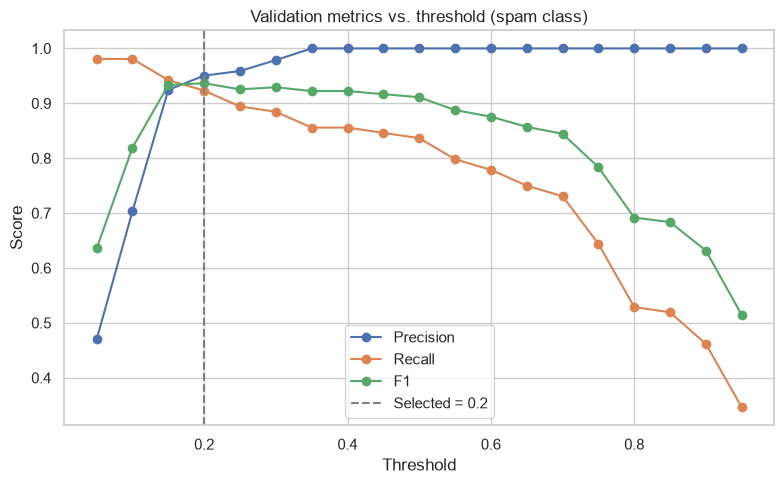

In [15]:
# Rule: highest F1 among thresholds that keep spam precision >= MIN_PRECISION
MIN_PRECISION = 0.95
eligible = threshold_df[threshold_df["Precision"] >= MIN_PRECISION]
pool = eligible if len(eligible) else threshold_df
# On ties, prefer the higher (more conservative) threshold
BEST_THRESHOLD = float(pool.loc[pool["F1"] == pool["F1"].max(), "Threshold"].max())
print(f"Selected threshold: {BEST_THRESHOLD}  (min precision rule: {MIN_PRECISION})")

plt.figure(figsize=(8, 5))
for col in ["Precision", "Recall", "F1"]:
    plt.plot(threshold_df["Threshold"], threshold_df[col], marker="o", label=col)
plt.axvline(BEST_THRESHOLD, color="grey", linestyle="--", label=f"Selected = {BEST_THRESHOLD}")
plt.title("Validation metrics vs. threshold (spam class)")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
save_fig("05_threshold_tuning")
plt.show()

## 7. Final evaluation on the test set
The chosen model is trained on the full training set and evaluated **once** on the test set, at the default 0.5 threshold and at the tuned one.

In [16]:
final_model = clone(pipelines[best_name]).fit(X_train, y_train)
spam_col = list(final_model.classes_).index("spam")
test_proba = final_model.predict_proba(X_test)[:, spam_col]

summary = []
preds = {}
for t in [0.5, BEST_THRESHOLD]:
    pred = np.where(test_proba >= t, "spam", "ham")
    preds[t] = pred
    summary.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label="spam", zero_division=0),
        "Recall": recall_score(y_test, pred, pos_label="spam"),
        "F1": f1_score(y_test, pred, pos_label="spam"),
    })
test_summary = pd.DataFrame(summary).drop_duplicates("Threshold").set_index("Threshold")
print(f"Model: {best_name}")
test_summary.round(4)

Model: Naive Bayes


,Accuracy,Precision,Recall,F1
Threshold,,,,
0.5,0.9797,1.0000,0.8397,0.9129
0.2,0.9797,0.9104,0.9313,0.9208


In [17]:
print(f"Classification report at threshold {BEST_THRESHOLD}:\n")
print(classification_report(y_test, preds[BEST_THRESHOLD], digits=3))

Classification report at threshold 0.2:

              precision    recall  f1-score   support

         ham      0.990     0.987     0.988       902
        spam      0.910     0.931     0.921       131

    accuracy                          0.980      1033
   macro avg      0.950     0.959     0.955      1033
weighted avg      0.980     0.980     0.980      1033



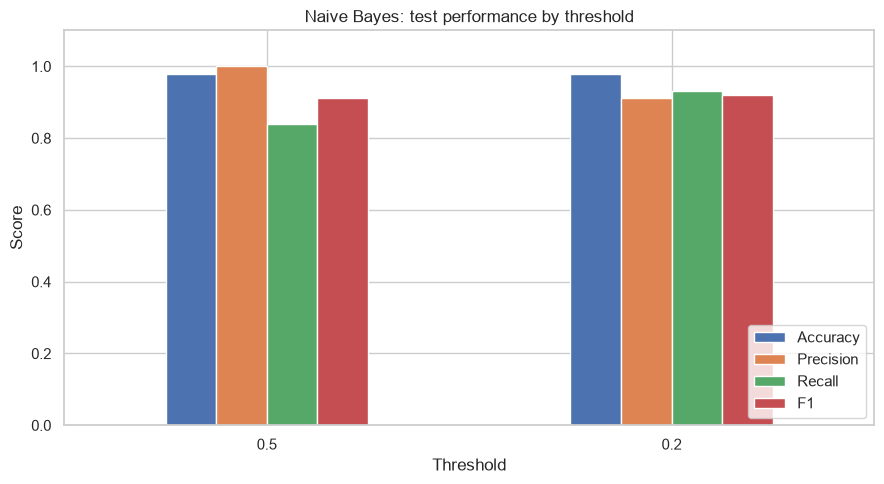

In [18]:
test_summary.plot(kind="bar", figsize=(9, 5))
plt.title(f"{best_name}: test performance by threshold")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
save_fig("06_threshold_comparison")
plt.show()

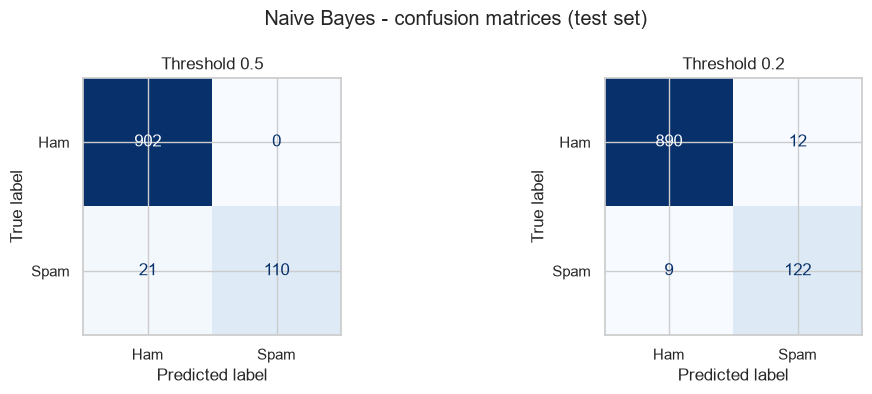

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t in zip(axes, [0.5, BEST_THRESHOLD]):
    cm = confusion_matrix(y_test, preds[t], labels=["ham", "spam"])
    ConfusionMatrixDisplay(cm, display_labels=["Ham", "Spam"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Threshold {t}")
fig.suptitle(f"{best_name} - confusion matrices (test set)")
save_fig("07_confusion_matrices")
plt.show()

## 8. Error analysis

In [20]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": preds[BEST_THRESHOLD],
    "Spam_Probability": test_proba,
    "Original_Message": df.loc[y_test.index, "message"],
})
pd.set_option("display.max_colwidth", 140)

missed_spam = results[(results["Actual"] == "spam") & (results["Predicted"] == "ham")]
false_alarms = results[(results["Actual"] == "ham") & (results["Predicted"] == "spam")]

print(f"Missed spam (false negatives): {len(missed_spam)}")
display(missed_spam.sort_values("Spam_Probability", ascending=False)[["Original_Message", "Spam_Probability"]].head(10))

print(f"Real messages blocked (false positives): {len(false_alarms)}")
display(false_alarms.sort_values("Spam_Probability", ascending=False)[["Original_Message", "Spam_Probability"]].head(10))

Missed spam (false negatives): 9


,Original_Message,Spam_Probability
2906,"Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p ...",0.180339
660,"SMS. ac sun0819 posts HELLO:""You seem cool, wanted to say hi. HI!!!"" Stop? Send STOP to 62468",0.180014
5058,"Latest News! Police station toilet stolen, cops have nothing to go on!",0.160131
3977,"accordingly. I repeat, just text the word ok on your mobile phone and send",0.110549
3946,Missed call alert. These numbers called but left no message. 07008009200,0.080149
4496,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,0.076026
4985,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?,0.034975
3887,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ...",0.032930
2301,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...,0.023409


Real messages blocked (false positives): 12


,Original_Message,Spam_Probability
2888,Your bill at 3 is £33.65 so thats not bad!,0.430143
1251,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",0.416466
2187,Hmm...Bad news...Hype park plaza $700 studio taken...Only left 2 bedrm-$900...,0.382264
4296,Have you laid your airtel line to rest?,0.295007
658,Did u receive my msg?,0.288077
75,I am waiting machan. Call me once you free.,0.285898
4318,"Received, understood n acted upon!",0.277126
2946,Or remind me in a few hrs.,0.260334
4132,"When you get free, call me",0.246719
5023,Gr8. So how do you handle the victoria island traffic. Plus when's the album due,0.208929


In [21]:
# Which words push a message towards spam / ham?
tfidf_step = final_model.named_steps["tfidf"]
clf = final_model.named_steps["clf"]
vocab = np.array(tfidf_step.get_feature_names_out())

if hasattr(clf, "feature_log_prob_"):
    classes = list(clf.classes_)
    score = clf.feature_log_prob_[classes.index("spam")] - clf.feature_log_prob_[classes.index("ham")]
elif hasattr(clf, "coef_"):
    score = clf.coef_[0] if list(clf.classes_)[1] == "spam" else -clf.coef_[0]
else:
    score = None

if score is not None:
    order = np.argsort(score)
    top = pd.DataFrame({
        "Most spam-like": vocab[order[::-1][:15]],
        "Most ham-like": vocab[order[:15]],
    })
    display(top)
else:
    print("This model type has no simple per-word weights.")

,Most spam-like,Most ham-like
0,call numtoken,gt
1,claim,lt
2,urltoken,ok
3,prize,lt gt
4,currencytoken numtoken,come
5,currencytoken,lor
6,numtoken prize,home
7,box numtoken,da
8,guaranteed,going
9,numtoken cash,got


## 9. Save the model and predict new messages

In [22]:
joblib.dump({"model": final_model, "threshold": BEST_THRESHOLD}, "spam_model.joblib")

def predict_sms(messages, model=final_model, threshold=BEST_THRESHOLD):
    """Return a DataFrame with the spam probability and label for raw SMS text."""
    cleaned = [clean_text(m) for m in messages]
    col = list(model.classes_).index("spam")
    proba = model.predict_proba(cleaned)[:, col]
    return pd.DataFrame({
        "Message": messages,
        "Spam_Probability": proba.round(4),
        "Prediction": np.where(proba >= threshold, "Spam", "Ham"),
    })

sample_messages = [
    "Congratulations! You have won a free prize. Click now!",
    "Hey, are we meeting tomorrow?",
    "URGENT! Claim your cash reward of 1000 now, call 09061701461",
    "Please call me when you reach home.",
    "Free entry in a weekly competition. Text WIN to 80086 to enter",
]
predict_sms(sample_messages)

,Message,Spam_Probability,Prediction
0,Congratulations! You have won a free prize. Click now!,0.8400,Spam
1,"Hey, are we meeting tomorrow?",0.0069,Ham
2,"URGENT! Claim your cash reward of 1000 now, call 09061701461",0.9548,Spam
3,Please call me when you reach home.,0.0640,Ham
4,Free entry in a weekly competition. Text WIN to 80086 to enter,0.8884,Spam


## 10. Summary

In [23]:
best_row = test_summary.loc[BEST_THRESHOLD]
print(f"""
Model selected (best CV F1): {best_name}
Decision threshold (validation, precision >= {MIN_PRECISION}): {BEST_THRESHOLD}

Test set results at that threshold:
  Accuracy : {best_row['Accuracy']:.4f}
  Precision: {best_row['Precision']:.4f}  (of messages flagged as spam, how many really were)
  Recall   : {best_row['Recall']:.4f}  (of all real spam, how much was caught)
  F1       : {best_row['F1']:.4f}
  Missed spam: {len(missed_spam)} | Real messages blocked: {len(false_alarms)}
""")


Model selected (best CV F1): Naive Bayes
Decision threshold (validation, precision >= 0.95): 0.2

Test set results at that threshold:
  Accuracy : 0.9797
  Precision: 0.9104  (of messages flagged as spam, how many really were)
  Recall   : 0.9313  (of all real spam, how much was caught)
  F1       : 0.9208
  Missed spam: 9 | Real messages blocked: 12



### Key takeaways
- The data is imbalanced, so **spam-class precision, recall and F1** were used instead of accuracy.
- Duplicates were removed **before** splitting, and TF-IDF was fitted **inside** each pipeline, which avoids leakage into the test set.
- The default 0.5 threshold tends to favour precision over recall; tuning the threshold on a validation set recovers more spam while a precision floor protects real messages.

### Limitations
- The dataset is small and dated (mostly UK/Singapore English SMS from the 2000s). Modern spam, other languages, and Hinglish-style messages would need new training data.
- Bag-of-words ignores word order and context; spammers can also adapt their wording.

### Possible next steps
- Try Linear SVM or Complement Naive Bayes, and tune TF-IDF settings with `GridSearchCV`.
- Add message-length and digit-count features.
- Try transformer embeddings (for example DistilBERT) and compare against this baseline.
- Wrap `predict_sms` in a small Streamlit or Flask app.